Vasu Sharma


2026B15310445

CSE AIML 6

Batch 7 - Data Analyst

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
files.upload()  # Choose product_events.csv

df = pd.read_csv("product_events.csv")
print("Rows loaded:", len(df))
display(df.head())

Saving product_events.csv to product_events.csv
Rows loaded: 1284


,event_id,user_id,session_id,event,timestamp,device,source
0,E00001,U0001,S00001,visit,2026-08-22 13:15:00,Mobile,Social
1,E00002,U0001,S00001,search,2026-08-22 13:17:00,Mobile,Social
2,E00003,U0001,S00002,visit,2026-08-29 11:47:00,Mobile,Social
3,E00004,U0001,S00002,search,2026-08-29 11:48:00,Mobile,Social
4,E00005,U0001,S00003,visit,2026-09-02 09:57:00,Mobile,Social


In [2]:
print("Missing values before cleaning:")
print(df.isna().sum())

# Turn timestamps into proper datetime values.
df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")

allowed = ["visit", "search", "view_product", "add_to_cart", "purchase"]
df = df.dropna(subset=["user_id", "session_id", "timestamp", "event"])
df = df[df["user_id"].astype(str).str.strip() != ""]
df = df[df["event"].isin(allowed)]

# One row = one event; repeated copies are not new activity.
print("Repeated events:", df.duplicated(["user_id", "session_id", "event", "timestamp"]).sum())
df = df.drop_duplicates(["user_id", "session_id", "event", "timestamp"])

# Every session ID should belong to just one user.
bad_ids = df.groupby("session_id")["user_id"].nunique()
bad_ids = bad_ids[bad_ids > 1].index
df = df[~df["session_id"].isin(bad_ids)].copy()

# Sort events so the funnel follows time order.
df = df.sort_values(["user_id", "session_id", "timestamp"]).reset_index(drop=True)
print("Clean rows:", len(df))
print("Users:", df["user_id"].nunique(), "Sessions:", df["session_id"].nunique())
print("Session IDs with multiple users removed:", len(bad_ids))
display(df.head())

Missing values before cleaning:
event_id      0
user_id       1
session_id    0
event         0
timestamp     0
device        0
source        0
dtype: int64
Repeated events: 14
Clean rows: 1267
Users: 180 Sessions: 496
Session IDs with multiple users removed: 0


,event_id,user_id,session_id,event,timestamp,device,source
0,E00001,U0001,S00001,visit,2026-08-22 13:15:00,Mobile,Social
1,E00002,U0001,S00001,search,2026-08-22 13:17:00,Mobile,Social
2,E00003,U0001,S00002,visit,2026-08-29 11:47:00,Mobile,Social
3,E00004,U0001,S00002,search,2026-08-29 11:48:00,Mobile,Social
4,E00005,U0001,S00003,visit,2026-09-02 09:57:00,Mobile,Social


In [3]:
gap = df.groupby("session_id")["timestamp"].diff().dt.total_seconds() / 60
print("Gaps over 30 minutes inside a session:", (gap > 30).sum())

sessions_per_user = df.groupby("user_id")["session_id"].nunique()
print("Users with more than one session:", (sessions_per_user > 1).sum())

# Verify the events are now in time order within each session.
wrong_order = df.groupby("session_id")["timestamp"].diff().dt.total_seconds().lt(0).sum()
print("Out-of-order events after sorting:", wrong_order)

Gaps over 30 minutes inside a session: 0
Users with more than one session: 149
Out-of-order events after sorting: 0


Funnel summary:


,sessions,% of visits,% from previous step
visit,496,100.0,100.0
view_product,356,71.8,71.8
add_to_cart,158,31.9,44.4
purchase,73,14.7,46.2


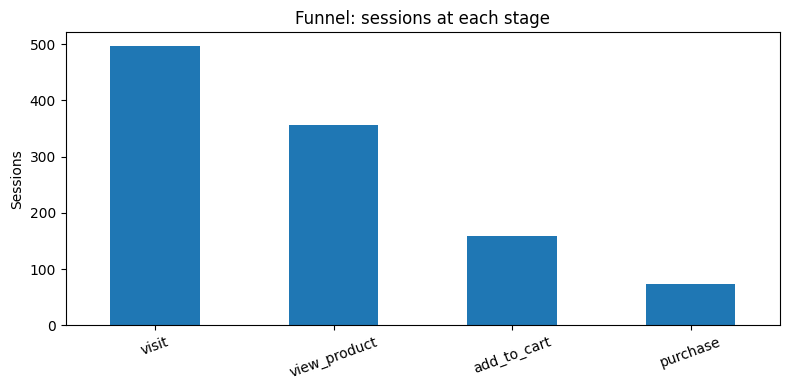

In [4]:
stages = ["visit", "view_product", "add_to_cart", "purchase"]

def make_funnel(data, session_column="session_id", steps=stages):
    results = []
    for sid, part in data.groupby(session_column):
        part = part.sort_values("timestamp")
        row = {
            "session": sid,
            "user_id": part["user_id"].iloc[0],
            "device": part["device"].iloc[0],
            "source": part["source"].iloc[0]
        }
        last_time = part["timestamp"].min()
        active = True
        for step in steps:
            hits = part.loc[(part["event"] == step) &
                            (part["timestamp"] >= last_time), "timestamp"]
            if active and not hits.empty:
                row[step] = 1
                last_time = hits.iloc[0]
            else:
                row[step] = 0
                active = False
        results.append(row)
    return pd.DataFrame(results)

funnel = make_funnel(df)
counts = funnel[stages].sum()
summary = pd.DataFrame({
    "sessions": counts,
    "% of visits": (counts / counts["visit"] * 100).round(1),
    "% from previous step": (counts / counts.shift(1) * 100).round(1)
})
summary.loc["visit", "% from previous step"] = 100
print("Funnel summary:")
display(summary)

summary["sessions"].plot(kind="bar", figsize=(8, 4), title="Funnel: sessions at each stage")
plt.ylabel("Sessions")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [5]:
values = funnel["purchase"].to_numpy()
rng = np.random.default_rng(16)
boot_rates = []
for _ in range(1000):
    sample = rng.choice(values, size=len(values), replace=True)
    boot_rates.append(sample.mean())

low, high = np.percentile(boot_rates, [2.5, 97.5])
print(f"Purchase conversion rate: {values.mean():.1%}")
print(f"95% bootstrap interval: {low:.1%} to {high:.1%}")

Purchase conversion rate: 14.7%
95% bootstrap interval: 11.7% to 17.7%


In [6]:
# Assign each user to their first calendar week.
df["week"] = df["timestamp"].dt.to_period("W").apply(lambda x: x.start_time)
first_week = df.groupby("user_id")["week"].min()
funnel["cohort"] = funnel["user_id"].map(first_week).dt.strftime("%Y-%m-%d")

for column in ["device", "source", "cohort"]:
    table = funnel.groupby(column).agg(
        sessions=("visit", "sum"),
        purchases=("purchase", "sum")
    )
    table["purchase_rate_%"] = (table["purchases"] / table["sessions"] * 100).round(1)
    print("\nConversion by", column)
    display(table)

# NumPy comparison: difference between Mobile and Desktop purchase rates.
mobile = funnel.loc[funnel["device"] == "Mobile", "purchase"].to_numpy()
desktop = funnel.loc[funnel["device"] == "Desktop", "purchase"].to_numpy()
if len(mobile) and len(desktop):
    differences = []
    for _ in range(1000):
        m = rng.choice(mobile, size=len(mobile), replace=True).mean()
        d = rng.choice(desktop, size=len(desktop), replace=True).mean()
        differences.append(m - d)
    lo, hi = np.percentile(differences, [2.5, 97.5])
    print(f"\nMobile minus Desktop purchase rate: {np.mean(mobile)-np.mean(desktop):.1%}")
    print(f"95% bootstrap interval for difference: {lo:.1%} to {hi:.1%}")


Conversion by device


,sessions,purchases,purchase_rate_%
device,,,
Desktop,144,29,20.1
Mobile,313,38,12.1
Tablet,39,6,15.4



Conversion by source


,sessions,purchases,purchase_rate_%
source,,,
Ads,94,10,10.6
Organic,229,43,18.8
Referral,36,3,8.3
Social,137,17,12.4



Conversion by cohort


,sessions,purchases,purchase_rate_%
cohort,,,
2026-07-06,53,4,7.5
2026-07-13,52,13,25.0
2026-07-20,46,3,6.5
2026-07-27,62,13,21.0
2026-08-03,69,10,14.5
2026-08-10,49,7,14.3
2026-08-17,64,7,10.9
2026-08-24,64,9,14.1
2026-08-31,37,7,18.9



Mobile minus Desktop purchase rate: -8.0%
95% bootstrap interval for difference: -14.9% to -0.7%


Weekly cohort retention (%):


week_number,0,1,2,3
cohort,,,,
2026-07-06,100.0,40.0,30.0,30.0
2026-07-13,100.0,58.8,47.1,17.6
2026-07-20,100.0,50.0,22.2,33.3
2026-07-27,100.0,66.7,33.3,28.6
2026-08-03,100.0,63.6,27.3,18.2
2026-08-10,100.0,36.4,31.8,9.1
2026-08-17,100.0,61.9,28.6,28.6
2026-08-24,100.0,44.0,32.0,8.0
2026-08-31,100.0,42.9,14.3,35.7


Users who returned for a second session: 149
Repeat-session user rate: 82.8%


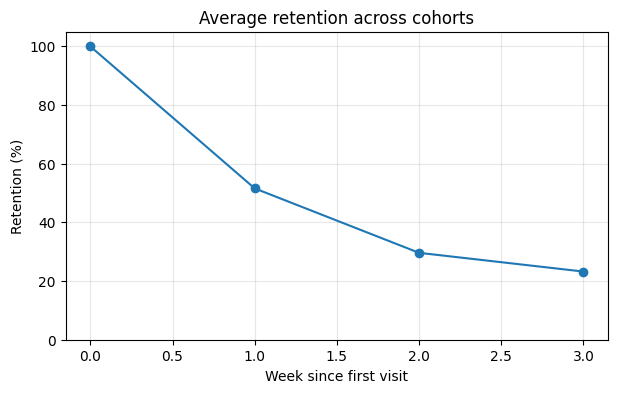

In [7]:
weekly_users = df[["user_id", "week"]].drop_duplicates().copy()
weekly_users["cohort"] = weekly_users["user_id"].map(first_week)
weekly_users["week_number"] = (
    (weekly_users["week"] - weekly_users["cohort"]).dt.days // 7
)

cohort_counts = weekly_users.groupby(["cohort", "week_number"])["user_id"].nunique().unstack(fill_value=0)
retention = (cohort_counts.div(cohort_counts[0], axis=0) * 100).round(1)
print("Weekly cohort retention (%):")
display(retention)

print("Users who returned for a second session:", (sessions_per_user >= 2).sum())
print("Repeat-session user rate:", f"{(sessions_per_user >= 2).mean():.1%}")

retention.mean().plot(marker="o", title="Average retention across cohorts", figsize=(7, 4))
plt.ylabel("Retention (%)")
plt.xlabel("Week since first visit")
plt.ylim(0, 105)
plt.grid(alpha=0.3)
plt.show()

In [8]:
def add_window_sessions(data, minutes):
    copy = data.sort_values(["user_id", "timestamp"]).copy()
    gap_minutes = copy.groupby("user_id")["timestamp"].diff().dt.total_seconds() / 60
    new_session = gap_minutes.isna() | (gap_minutes > minutes)
    session_number = new_session.groupby(copy["user_id"]).cumsum()
    copy["window_session"] = copy["user_id"] + "_" + session_number.astype(str)
    return copy

for minutes in [15, 30, 60]:
    updated = add_window_sessions(df, minutes)
    test_funnel = make_funnel(updated, "window_session")
    print(f"{minutes}-minute window: {len(test_funnel)} sessions, "
          f"purchase rate {test_funnel['purchase'].mean():.1%}")

15-minute window: 494 sessions, purchase rate 14.8%
30-minute window: 444 sessions, purchase rate 16.2%
60-minute window: 367 sessions, purchase rate 18.5%


In [9]:
simple_steps = ["visit", "view_product", "purchase"]
simple_funnel = make_funnel(df, steps=simple_steps)
print("4-step completion rate:", f"{funnel['purchase'].mean():.1%}")
print("3-step completion rate:", f"{simple_funnel['purchase'].mean():.1%}")
print("Different definitions can give different conversion rates.")

4-step completion rate: 14.7%
3-step completion rate: 18.3%
Different definitions can give different conversion rates.


In [10]:
df.to_csv("clean_events.csv", index=False)
summary.to_csv("funnel_summary.csv")
retention.to_csv("weekly_cohort_retention.csv")
funnel.to_csv("session_funnel.csv", index=False)
print("Saved: clean_events.csv, funnel_summary.csv, weekly_cohort_retention.csv, session_funnel.csv")

Saved: clean_events.csv, funnel_summary.csv, weekly_cohort_retention.csv, session_funnel.csv


In [ ]:
from google.colab import drive
drive.mount('/content/drive')